In [ ]:
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42); tf.random.set_seed(42)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
x_train = x_train.astype("float32") / 255
x_test  = x_test.astype("float32") / 255
x_train_cnn = x_train[..., np.newaxis]
x_test_cnn  = x_test[..., np.newaxis]

In [ ]:
import time

def run(model, name, x_tr=x_train_cnn, y_tr=y_train, epochs=10, **fit_kw):
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    t0 = time.time()
    h = model.fit(x_tr, y_tr, epochs=epochs, batch_size=128,
                  validation_split=0.1, verbose=2, **fit_kw)
    dt = time.time() - t0
    loss, acc = model.evaluate(x_test_cnn, y_test, verbose=0)
    print(f"{name}: test acc={acc:.4f} | params={model.count_params():,} | {dt:.0f}s")
    return h, acc

results = {}   # nom -> (history, test_acc)

In [ ]:
def cnn_base():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")])

results["A base"] = run(cnn_base(), "A base")

Epoch 1/10
422/422 - 10s - 23ms/step - accuracy: 0.9183 - loss: 0.2846 - val_accuracy: 0.9730 - val_loss: 0.0999
Epoch 2/10
422/422 - 2s - 4ms/step - accuracy: 0.9715 - loss: 0.0984 - val_accuracy: 0.9787 - val_loss: 0.0732
Epoch 3/10
422/422 - 2s - 4ms/step - accuracy: 0.9811 - loss: 0.0645 - val_accuracy: 0.9828 - val_loss: 0.0621
Epoch 4/10
422/422 - 2s - 4ms/step - accuracy: 0.9860 - loss: 0.0479 - val_accuracy: 0.9833 - val_loss: 0.0583
Epoch 5/10
422/422 - 2s - 4ms/step - accuracy: 0.9893 - loss: 0.0372 - val_accuracy: 0.9837 - val_loss: 0.0578
Epoch 6/10
422/422 - 2s - 4ms/step - accuracy: 0.9917 - loss: 0.0295 - val_accuracy: 0.9843 - val_loss: 0.0579
Epoch 7/10
422/422 - 2s - 4ms/step - accuracy: 0.9939 - loss: 0.0235 - val_accuracy: 0.9838 - val_loss: 0.0598
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9956 - loss: 0.0182 - val_accuracy: 0.9835 - val_loss: 0.0602
Epoch 9/10
422/422 - 2s - 4ms/step - accuracy: 0.9968 - loss: 0.0141 - val_accuracy: 0.9838 - val_loss: 0.0639

In [ ]:
def cnn_conv():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")])

results["B +Conv/Pool"] = run(cnn_conv(), "B +Conv/Pool")

Epoch 1/10
422/422 - 9s - 22ms/step - accuracy: 0.9276 - loss: 0.2467 - val_accuracy: 0.9830 - val_loss: 0.0638
Epoch 2/10
422/422 - 2s - 5ms/step - accuracy: 0.9789 - loss: 0.0678 - val_accuracy: 0.9870 - val_loss: 0.0528
Epoch 3/10
422/422 - 2s - 5ms/step - accuracy: 0.9846 - loss: 0.0482 - val_accuracy: 0.9853 - val_loss: 0.0488
Epoch 4/10
422/422 - 2s - 4ms/step - accuracy: 0.9880 - loss: 0.0382 - val_accuracy: 0.9878 - val_loss: 0.0446
Epoch 5/10
422/422 - 2s - 4ms/step - accuracy: 0.9902 - loss: 0.0308 - val_accuracy: 0.9892 - val_loss: 0.0403
Epoch 6/10
422/422 - 2s - 4ms/step - accuracy: 0.9920 - loss: 0.0250 - val_accuracy: 0.9882 - val_loss: 0.0420
Epoch 7/10
422/422 - 2s - 4ms/step - accuracy: 0.9937 - loss: 0.0206 - val_accuracy: 0.9887 - val_loss: 0.0419
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9948 - loss: 0.0172 - val_accuracy: 0.9883 - val_loss: 0.0430
Epoch 9/10
422/422 - 2s - 4ms/step - accuracy: 0.9958 - loss: 0.0138 - val_accuracy: 0.9887 - val_loss: 0.0469


In [ ]:
def cnn_dense():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")])

results["C +Dense"] = run(cnn_dense(), "C +Dense")

Epoch 1/10
422/422 - 6s - 14ms/step - accuracy: 0.9237 - loss: 0.2546 - val_accuracy: 0.9740 - val_loss: 0.0886
Epoch 2/10
422/422 - 2s - 4ms/step - accuracy: 0.9769 - loss: 0.0751 - val_accuracy: 0.9823 - val_loss: 0.0649
Epoch 3/10
422/422 - 2s - 4ms/step - accuracy: 0.9857 - loss: 0.0481 - val_accuracy: 0.9842 - val_loss: 0.0592
Epoch 4/10
422/422 - 2s - 4ms/step - accuracy: 0.9899 - loss: 0.0336 - val_accuracy: 0.9833 - val_loss: 0.0595
Epoch 5/10
422/422 - 2s - 4ms/step - accuracy: 0.9931 - loss: 0.0234 - val_accuracy: 0.9850 - val_loss: 0.0599
Epoch 6/10
422/422 - 2s - 4ms/step - accuracy: 0.9953 - loss: 0.0166 - val_accuracy: 0.9838 - val_loss: 0.0646
Epoch 7/10
422/422 - 2s - 4ms/step - accuracy: 0.9963 - loss: 0.0128 - val_accuracy: 0.9833 - val_loss: 0.0709
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9972 - loss: 0.0100 - val_accuracy: 0.9862 - val_loss: 0.0602
Epoch 9/10
422/422 - 2s - 4ms/step - accuracy: 0.9966 - loss: 0.0101 - val_accuracy: 0.9863 - val_loss: 0.0617


In [ ]:
def cnn_dropout():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax")])

results["D +Dropout"] = run(cnn_dropout(), "D +Dropout")

Epoch 1/10
422/422 - 9s - 20ms/step - accuracy: 0.8789 - loss: 0.3832 - val_accuracy: 0.9812 - val_loss: 0.0676
Epoch 2/10
422/422 - 2s - 5ms/step - accuracy: 0.9620 - loss: 0.1277 - val_accuracy: 0.9873 - val_loss: 0.0472
Epoch 3/10
422/422 - 2s - 4ms/step - accuracy: 0.9691 - loss: 0.1020 - val_accuracy: 0.9878 - val_loss: 0.0402
Epoch 4/10
422/422 - 2s - 4ms/step - accuracy: 0.9751 - loss: 0.0831 - val_accuracy: 0.9897 - val_loss: 0.0344
Epoch 5/10
422/422 - 2s - 4ms/step - accuracy: 0.9783 - loss: 0.0712 - val_accuracy: 0.9902 - val_loss: 0.0347
Epoch 6/10
422/422 - 2s - 4ms/step - accuracy: 0.9799 - loss: 0.0647 - val_accuracy: 0.9923 - val_loss: 0.0309
Epoch 7/10
422/422 - 2s - 4ms/step - accuracy: 0.9809 - loss: 0.0597 - val_accuracy: 0.9920 - val_loss: 0.0310
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9822 - loss: 0.0561 - val_accuracy: 0.9913 - val_loss: 0.0322
Epoch 9/10
422/422 - 2s - 4ms/step - accuracy: 0.9834 - loss: 0.0530 - val_accuracy: 0.9920 - val_loss: 0.0289


In [ ]:
def cnn_aug():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.1, 0.1),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")])

results["E +Augmentation"] = run(cnn_aug(), "E +Augmentation", epochs=20)

Epoch 1/20
422/422 - 8s - 20ms/step - accuracy: 0.7684 - loss: 0.7061 - val_accuracy: 0.9722 - val_loss: 0.0916
Epoch 2/20
422/422 - 3s - 7ms/step - accuracy: 0.9113 - loss: 0.2864 - val_accuracy: 0.9820 - val_loss: 0.0612
Epoch 3/20
422/422 - 3s - 7ms/step - accuracy: 0.9352 - loss: 0.2113 - val_accuracy: 0.9842 - val_loss: 0.0523
Epoch 4/20
422/422 - 3s - 7ms/step - accuracy: 0.9451 - loss: 0.1743 - val_accuracy: 0.9845 - val_loss: 0.0508
Epoch 5/20
422/422 - 5s - 12ms/step - accuracy: 0.9535 - loss: 0.1534 - val_accuracy: 0.9853 - val_loss: 0.0472
Epoch 6/20
422/422 - 3s - 7ms/step - accuracy: 0.9571 - loss: 0.1368 - val_accuracy: 0.9845 - val_loss: 0.0492
Epoch 7/20
422/422 - 3s - 7ms/step - accuracy: 0.9621 - loss: 0.1236 - val_accuracy: 0.9887 - val_loss: 0.0387
Epoch 8/20
422/422 - 3s - 7ms/step - accuracy: 0.9643 - loss: 0.1137 - val_accuracy: 0.9878 - val_loss: 0.0397
Epoch 9/20
422/422 - 3s - 7ms/step - accuracy: 0.9661 - loss: 0.1086 - val_accuracy: 0.9885 - val_loss: 0.0406

A base             train=0.9974  val=0.9848  test=0.9837
B +Conv/Pool       train=0.9967  val=0.9863  test=0.9875
C +Dense           train=0.9974  val=0.9862  test=0.9832
D +Dropout         train=0.9849  val=0.9923  test=0.9921
E +Augmentation    train=0.9771  val=0.9897  test=0.9894


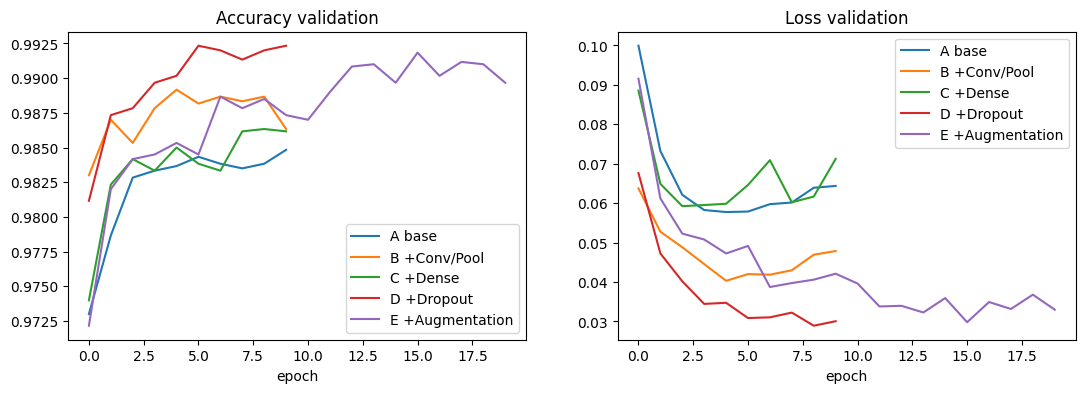

In [ ]:
for n, (h, acc) in results.items():
    print(f"{n:18s} train={h.history['accuracy'][-1]:.4f}  "
          f"val={h.history['val_accuracy'][-1]:.4f}  test={acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n, (h, _) in results.items():
    axes[0].plot(h.history["val_accuracy"], label=n)
    axes[1].plot(h.history["val_loss"], label=n)
axes[0].set_title("Accuracy validation"); axes[1].set_title("Loss validation")
for a in axes: a.set_xlabel("epoch"); a.legend()
plt.show()